In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras as keras
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix

2026-03-06 11:35:08.456985: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-03-06 11:35:08.457156: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-03-06 11:35:08.457246: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-03-06 11:35:11.159222: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [4]:
# 1. Define your 15 chosen categories (ensure these match your filenames exactly, minus the .npy)
categories = [
    'soccer ball', 'cookie', 'The Eiffel Tower', 'triangle', 'kangaroo', 
    'panda', 'windmill', 'mug', 'star', 'fish', 
    'octagon', 'jacket', 'key', 'penguin', 'snowflake'
]

samples_per_class = 7500
total_samples = samples_per_class * len(categories)

# Initialize empty arrays to hold our data and labels
X = np.empty((0, 784), dtype='float32')
y = np.empty((0,), dtype='int')

print("Loading and sampling {total_samples} images...")

# 2. Load, sample, and assign labels
for idx, category in enumerate(categories):
    file_path = f"full_numpy_bitmap_{category}.npy"
    
    # Load the numpy array
    data = np.load(file_path)
    
    # Slice exactly 7500 images
    data = data[:samples_per_class] 
    
    # Create an array of labels (0 to 14) for this specific category
    labels = np.full(samples_per_class, idx)
    
    # Append to our master arrays
    X = np.concatenate((X, data), axis=0)
    y = np.concatenate((y, labels), axis=0)
    
    print(f"Loaded {category} - Shape: {data.shape} - Label: {idx}")

# 3. Reshape for a 2D CNN
print("\nReshaping...")
# Reshape from flat 784 arrays into 28x28 grayscale image matrices with 1 color channel
X = X.reshape(-1, 28, 28, 1)


# 4. Split the Data (80% Train, 18% Validation, 2% Test)
print("Splitting data into Train, Validation, and Test sets...")

# First split: 80% Train, 20% Temp (which we will split again)
# Using stratify=y ensures every split has an exactly equal amount of each category
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Second split: Divide the remaining 20% into 18% Validation and 2% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("\nData Preparation Complete!")
print(f"Training data shape: {X_train.shape}")
print(f"Validation data shape: {X_val.shape}")
print(f"Testing data shape: {X_test.shape}")

Loading and sampling {total_samples} images...
Loaded soccer ball - Shape: (7500, 784) - Label: 0
Loaded cookie - Shape: (7500, 784) - Label: 1
Loaded The Eiffel Tower - Shape: (7500, 784) - Label: 2
Loaded triangle - Shape: (7500, 784) - Label: 3
Loaded kangaroo - Shape: (7500, 784) - Label: 4
Loaded panda - Shape: (7500, 784) - Label: 5
Loaded windmill - Shape: (7500, 784) - Label: 6
Loaded mug - Shape: (7500, 784) - Label: 7
Loaded star - Shape: (7500, 784) - Label: 8
Loaded fish - Shape: (7500, 784) - Label: 9
Loaded octagon - Shape: (7500, 784) - Label: 10
Loaded jacket - Shape: (7500, 784) - Label: 11
Loaded key - Shape: (7500, 784) - Label: 12
Loaded penguin - Shape: (7500, 784) - Label: 13
Loaded snowflake - Shape: (7500, 784) - Label: 14

Reshaping...
Splitting data into Train, Validation, and Test sets...

Data Preparation Complete!
Training data shape: (90000, 28, 28, 1)
Validation data shape: (11250, 28, 28, 1)
Testing data shape: (11250, 28, 28, 1)


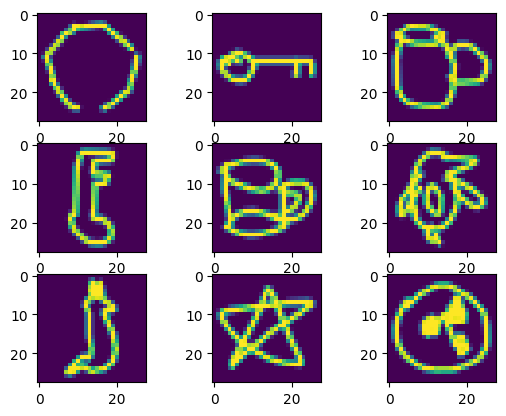

In [5]:
# Visual inspection, verify shaping worked
look = np.random.uniform (0, 90000, 9)

_, Z = plt.subplots (3, 3)

for i in range (0, 3):
    for j in range (0, 3):
        Z[i, j].imshow (X_train[int (look [i*3 + j])])


In [3]:
print("Building the baseline 2D CNN model...")

# 1. Define the Architecture
model = models.Sequential()

# First Convolutional Block (Extracts simple features like edges and lines)
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block (Extracts more complex features like curves and corners)
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block (Extracts high-level shapes)
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model.add(layers.Flatten()) # Flattens the 2D maps into a 1D array
model.add(layers.Dense(64, activation='relu')) # A standard hidden layer

# Output Layer (15 units for our 15 classes, Softmax to output probabilities)
model.add(layers.Dense(15, activation='softmax'))

# Print a summary of the model for your report
model.summary()

# 2. Compile the Model
# We use sparse_categorical_crossentropy because our labels are integers (0 to 14)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\nStarting Training (Experiment 1)...")

# 3. Train the Model
# batch_size=32 and epochs=10 are standard baseline hyper-parameters
history = model.fit(X_train, y_train, 
                    epochs=10, 
                    batch_size=32,
                    validation_data=(X_val, y_val))

print("\nTraining Complete!")

Building the baseline 2D CNN model...
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 flatten (Flatten)

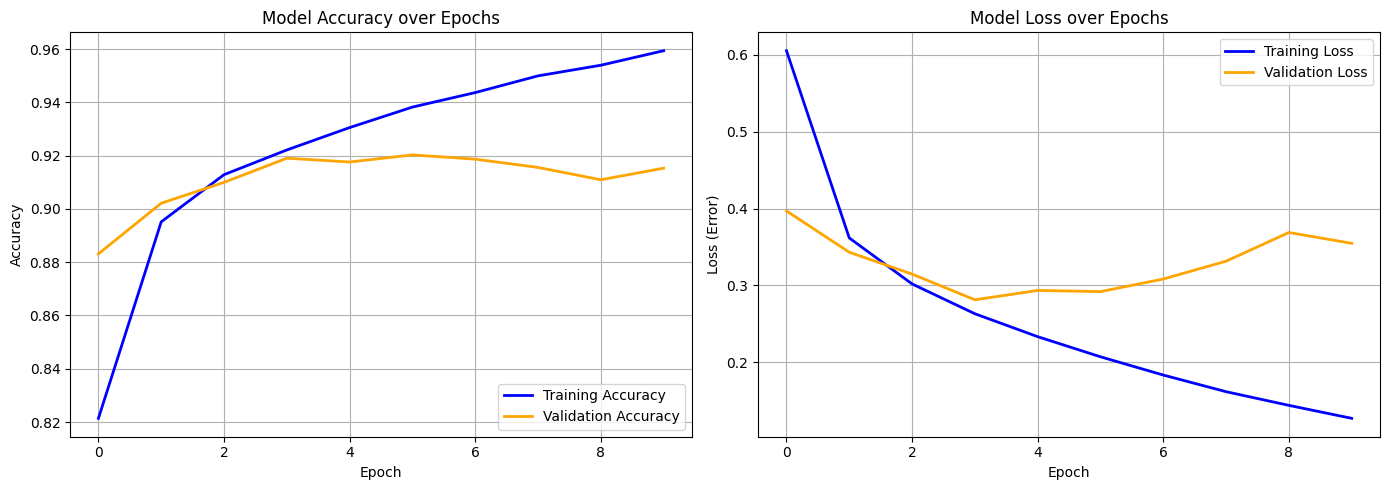

In [4]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [5]:
print("Building Experiment 2 Model (Adding Dropout)...")

# 1. Define the Architecture
model_2 = models.Sequential()

# First Convolutional Block 
model_2.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_2.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_2.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_2.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_2.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_2.add(layers.Flatten()) 
model_2.add(layers.Dense(64, activation='relu')) 

# NEW: The Dropout Layer
# This randomly ignores 50% of the neurons during each training step
model_2.add(layers.Dropout(0.5))


# Output Layer 
model_2.add(layers.Dense(15, activation='softmax'))

# Print summary
model_2.summary()

# 2. Compile the Model
model_2.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\nStarting Training (Experiment 2)...")

# 3. Train the Model
# We'll stick with batch_size=32 and epochs=10 so it's a fair comparison to Exp 1
history_2 = model_2.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=32,
                        validation_data=(X_val, y_val))

print("\nTraining Complete for Experiment 2!")

Building Experiment 2 Model (Adding Dropout)...
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 flatt

In [6]:
print("Building Experiment 2 Model (Adding Dropout)...")

# 1. Define the Architecture
model_2a = models.Sequential()

# First Convolutional Block 
model_2a.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_2a.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_2a.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_2a.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_2a.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_2a.add(layers.Flatten()) 
model_2a.add(layers.Dense(64, activation='relu')) 

# NEW: The Dropout Layer
# This randomly ignores 50% of the neurons during each training step
model_2a.add(layers.Dropout(0.5))


# Output Layer 
model_2a.add(layers.Dense(15, activation='softmax'))

# Print summary
model_2a.summary()

# 2. Compile the Model
model_2a.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\nStarting Training (Experiment 2)...")

# 3. Train the Model
# We'll stick with batch_size=32 and epochs=10 so it's a fair comparison to Exp 1
history_2a = model_2a.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=32,
                        validation_data=(X_val, y_val))

print("\nTraining Complete for Experiment 2!")

Building Experiment 2 Model (Adding Dropout)...
Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 flatt

In [7]:
print("Building Experiment 3 Model)...")

# 1. Define the Architecture
model_3= models.Sequential()

# First Convolutional Block 
model_3.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_3.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_3.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_3.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_3.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_3.add(layers.Flatten()) 
model_3.add(layers.Dense(64, activation='relu')) 

# NEW: The Dropout Layer
# This randomly ignores 50% of the neurons during each training step
model_3.add(layers.Dropout(0.5))


# Output Layer 
model_3.add(layers.Dense(15, activation='softmax'))

# Print summary
model_3.summary()

# 2. Compile the Model
model_3.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 3)...")

# 4. Train the Model
# We'll stick with batch_size=32 and epochs=10 so it's a fair comparison to Exp 1
history_3 = model_3.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=32,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 3!")

Building Experiment 3 Model)...
Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_9 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_10 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_11 (Conv2D)          (None, 3, 3, 64)          36928     
                                                                 
 flatten_3 (Flatten)  

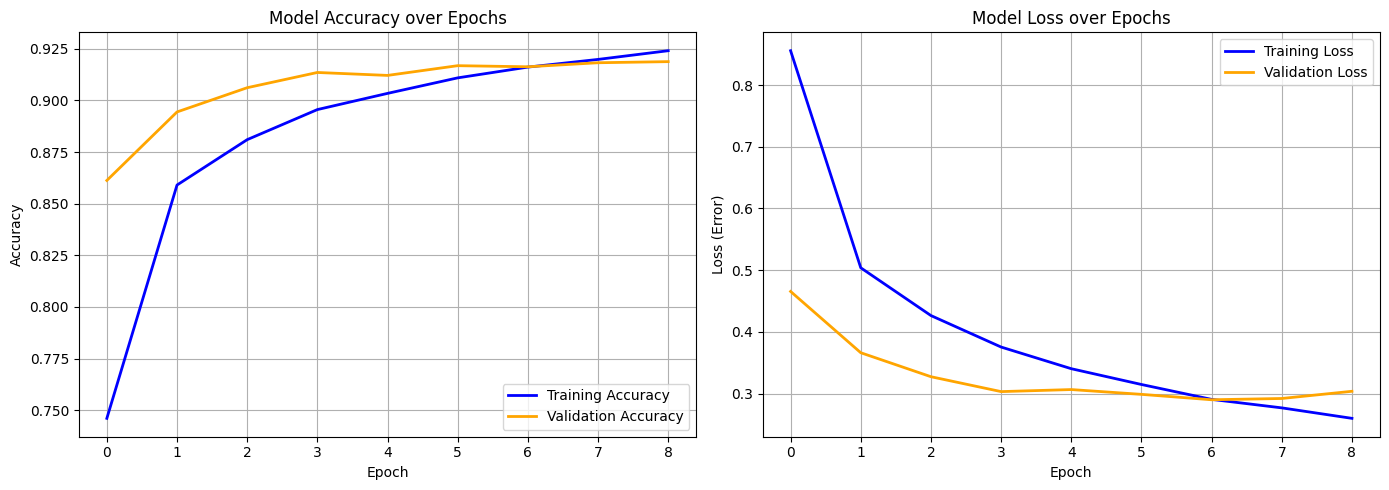

In [8]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_3.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_3.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_3.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_3.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [9]:
print("Evaluating final model on the unseen Test Set...")

# Evaluate the model on the test data
test_loss, test_accuracy = model_3.evaluate(X_test, y_test, verbose=1)

print(f"\nFinal Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

Evaluating final model on the unseen Test Set...
352/352 [==============================] - 3s 8ms/step - loss: 0.3230 - accuracy: 0.9089

Final Test Loss: 0.3230
Final Test Accuracy: 90.89%


Generating predictions...
1/1 [==============================] - 0s 39ms/step


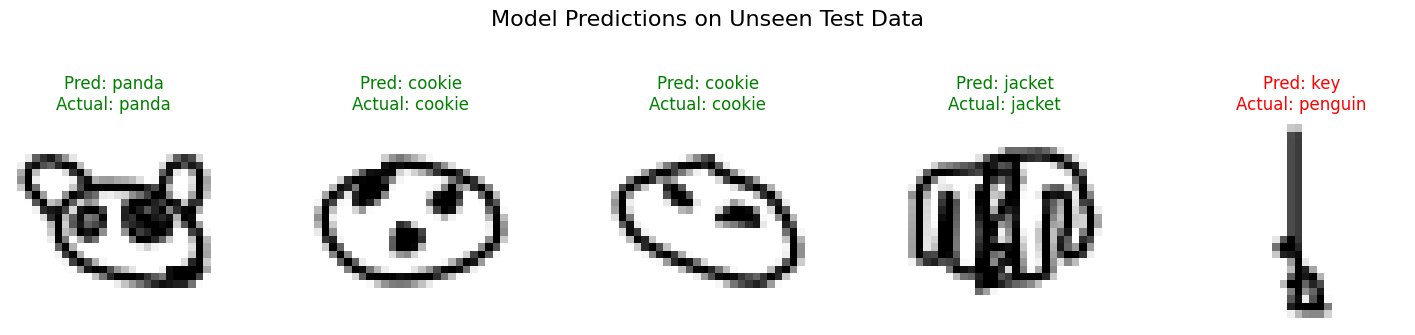

In [34]:
# 1. Map the integer labels back to our actual category names
class_names = [
    'soccer ball', 'cookie', 'The Eiffel Tower', 'triangle', 'kangaroo', 
    'panda', 'windmill', 'mug', 'star', 'fish', 
    'octagon', 'jacket', 'key', 'penguin', 'snowflake'
]

# 2. Pick 5 random images from the unseen Test Set
num_images = 5
random_indices = np.random.choice(len(X_test), num_images, replace=False)
sample_images = X_test[random_indices]
sample_labels = y_test[random_indices]

print("Generating predictions...")

# 3. Ask the model to predict these 5 images
# This returns an array of probabilities for all 15 classes for each image
predictions = model_3.predict(sample_images)

# 4. Set up the visualization
fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
fig.suptitle('Model Predictions on Unseen Test Data', fontsize=16, y=1.1)

for i, ax in enumerate(axes):
    # Reshape the image from (28, 28, 1) back to (28, 28) for Matplotlib
    img = sample_images[i].reshape(28, 28)
    
    # Get the index of the highest probability (the model's final guess)
    predicted_class_index = np.argmax(predictions[i])
    actual_class_index = sample_labels[i]
    
    # Display the image 
    # 'gray_r' reverses the colors so it looks like a black pen on white paper
    ax.imshow(img, cmap='gray_r') 
    ax.axis('off') # Hide the grid axes for a cleaner look
    
    # Color-code the text: Green if correct, Red if wrong
    color = 'green' if predicted_class_index == actual_class_index else 'red'
    
    # Create the title for each subplot
    title = f"Pred: {class_names[predicted_class_index]}\nActual: {class_names[actual_class_index]}"
    ax.set_title(title, color=color, fontsize=12)

plt.tight_layout()
plt.show()

In [11]:
print("Building Experiment 3 Model)...")

# 1. Define the Architecture
model_3a= models.Sequential()

# First Convolutional Block 
model_3a.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_3a.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_3a.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_3a.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_3a.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_3a.add(layers.Flatten()) 
model_3a.add(layers.Dense(64, activation='relu')) 

# NEW: The Dropout Layer
# This randomly ignores 50% of the neurons during each training step
model_3a.add(layers.Dropout(0.5))


# Output Layer 
model_3a.add(layers.Dense(15, activation='softmax'))

# Print summary
model_3a.summary()

# 2. Compile the Model
model_3a.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 3)...")

# 4. Train the Model
# We'll stick with batch_size=32 and epochs=10 so it's a fair comparison to Exp 1
history_3a = model_3a.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 3!")

Building Experiment 3 Model)...
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_12 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_13 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_9 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_14 (Conv2D)          (None, 3, 3, 64)          36928     
                                                                 
 flatten_4 (Flatten)  

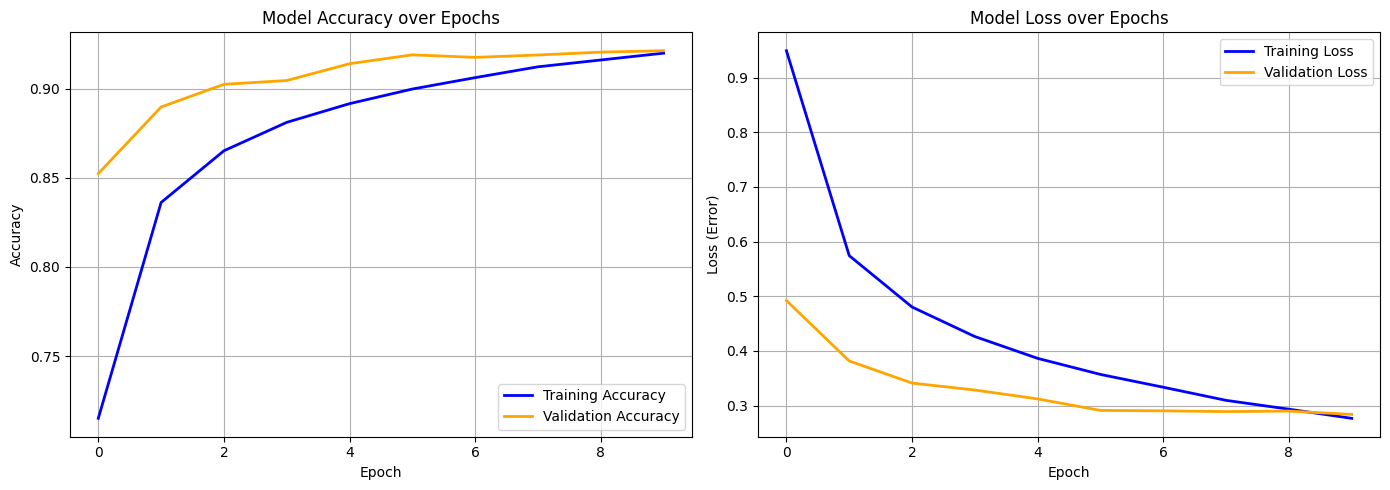

In [12]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_3a.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_3a.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_3a.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_3a.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [26]:
print("(Building Experiment 4 Model)...")

# 1. Define the Architecture
model_4= models.Sequential()

# Normalization layer
model_4.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_4.layers[0].adapt(X_train)

# First Convolutional Block 
model_4.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_4.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_4.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_4.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_4.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_4.add(layers.Flatten()) 
model_4.add(layers.Dense(64, activation='relu')) 

# The Dropout Layer - randomly ignores 50% of the neurons during each training step
model_4.add(layers.Dropout(0.5))


# Output Layer 
model_4.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_4.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_4.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 4)...")

# 4. Train the Model
history_4 = model_4.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 4!")

(Building Experiment 4 Model)...
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_3 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_9 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_10 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                     

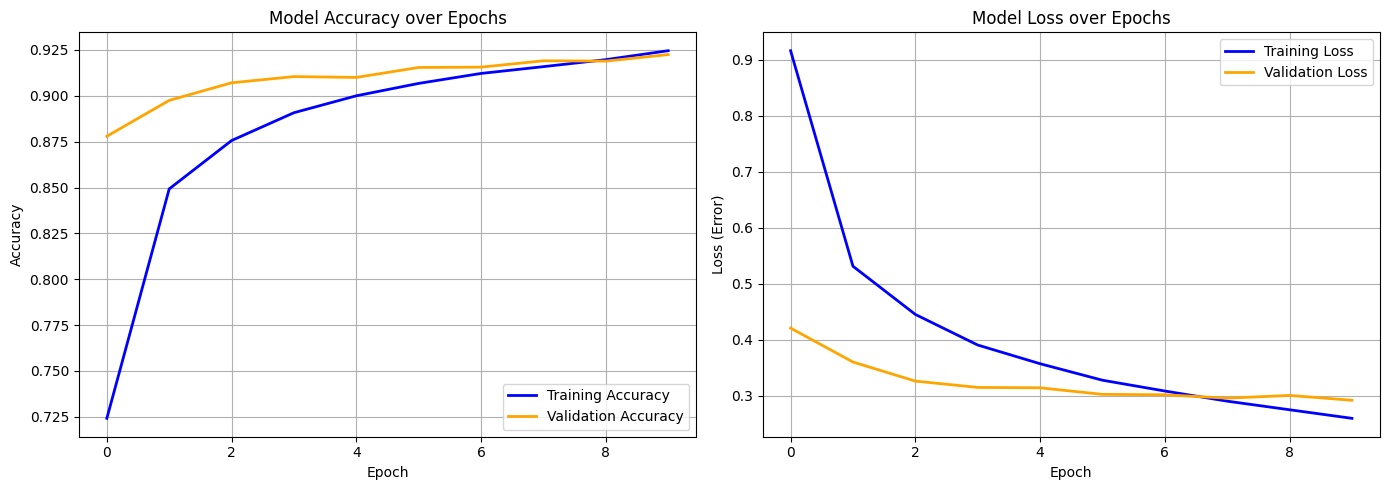

In [27]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_4.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_4.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_4.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_4.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [28]:
Z = model_4.predict(X_test, verbose=False)

Z

array([[1.4508349e-13, 8.8562421e-12, 4.2736928e-10, ..., 6.1520459e-12,
        7.1576250e-07, 1.6447085e-12],
       [2.1277575e-17, 3.0514216e-16, 1.9276516e-13, ..., 4.5259113e-15,
        6.2710259e-10, 1.5007932e-16],
       [6.2333382e-16, 7.4427694e-14, 2.7056903e-09, ..., 3.2414631e-13,
        7.4829649e-11, 9.9549586e-01],
       ...,
       [9.3058381e-18, 8.1149706e-16, 1.0395279e-10, ..., 4.1841365e-15,
        2.8693923e-13, 9.9952632e-01],
       [4.8106477e-14, 2.7211855e-16, 1.6774716e-16, ..., 1.0222431e-15,
        2.0527701e-12, 7.7090581e-16],
       [9.4949454e-03, 4.0657487e-02, 1.2481834e-04, ..., 7.0435423e-03,
        4.4716195e-05, 1.5053568e-04]], dtype=float32)

In [29]:
Z.shape

(11250, 15)

In [30]:
predictions = np.argmax(Z, axis=1)
predictions.shape

(11250,)

In [31]:
sum(predictions == y_test) / Z.shape[0]

0.9145777777777778

In [32]:
samples = np.random.randint(0, Z.shape[0], 1000)
predictions[samples]

array([ 9,  3, 12,  2,  4,  9,  2,  0,  4,  2,  1,  0, 12,  9,  4,  7,  4,
        2,  5, 11,  2, 10, 13,  6,  2, 14, 11,  6,  0, 11,  0,  2, 14,  0,
       12,  2, 14,  1,  8,  5,  9,  1, 10,  2, 13, 13,  8,  1,  1,  7,  0,
        0,  2,  8, 10, 12,  5, 11, 12,  0,  9,  9,  3, 12, 12,  0, 11,  6,
        8, 11,  9,  1,  6, 11,  6, 12,  9,  9, 14,  9,  0,  9, 12, 12, 14,
        2,  2,  1,  6,  2,  5,  3,  8, 12,  9, 10,  8, 14,  5, 14, 12,  3,
       13, 12,  3, 10, 11,  1, 14,  6, 10,  4,  1,  3,  0,  6,  2,  6, 10,
        8, 12, 14, 13, 11,  4, 10,  4, 11,  1, 13, 13,  8,  9, 13, 11, 10,
        5, 13,  4,  3,  8, 10,  4, 13, 11, 10,  0, 13,  2,  2, 12, 10,  0,
        6,  2,  9,  3,  2,  8, 10, 14,  0,  5,  2, 12,  5,  3, 11,  0, 14,
       10, 14,  7, 12,  8,  8, 12, 11, 12, 12,  1, 12, 12,  0, 13, 11,  4,
        1,  9, 10,  4,  3, 11, 11, 12, 11,  6, 11,  1,  6,  0,  0,  2,  6,
        1,  4,  1,  5,  2,  5,  8, 10,  6,  4,  3,  9,  1,  1,  0,  7,  2,
        1, 10,  5,  8,  6

In [33]:
predictions[samples] == y_test[samples]

array([ True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False, False,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True, False,  True,  True,  True,
       False,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True, False, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [19]:
wrong = np.where(predictions[samples] != y_test[samples])[0]
wrong

array([ 11,  13,  15,  25,  26,  39,  90,  92,  94, 100, 102, 110, 115,
       122, 125, 144, 178, 184, 221, 222, 235, 238, 244, 249, 259, 265,
       270, 275, 285, 299, 300, 307, 337, 342, 344, 359, 368, 370, 387,
       400, 417, 420, 422, 443, 454, 457, 469, 471, 472, 480, 486, 500,
       526, 551, 567, 590, 597, 613, 625, 638, 652, 656, 685, 688, 691,
       707, 710, 732, 756, 763, 777, 781, 791, 798, 811, 819, 826, 833,
       871, 875, 884, 889, 917, 924, 932, 957, 962, 969, 974, 975, 980,
       981, 996])

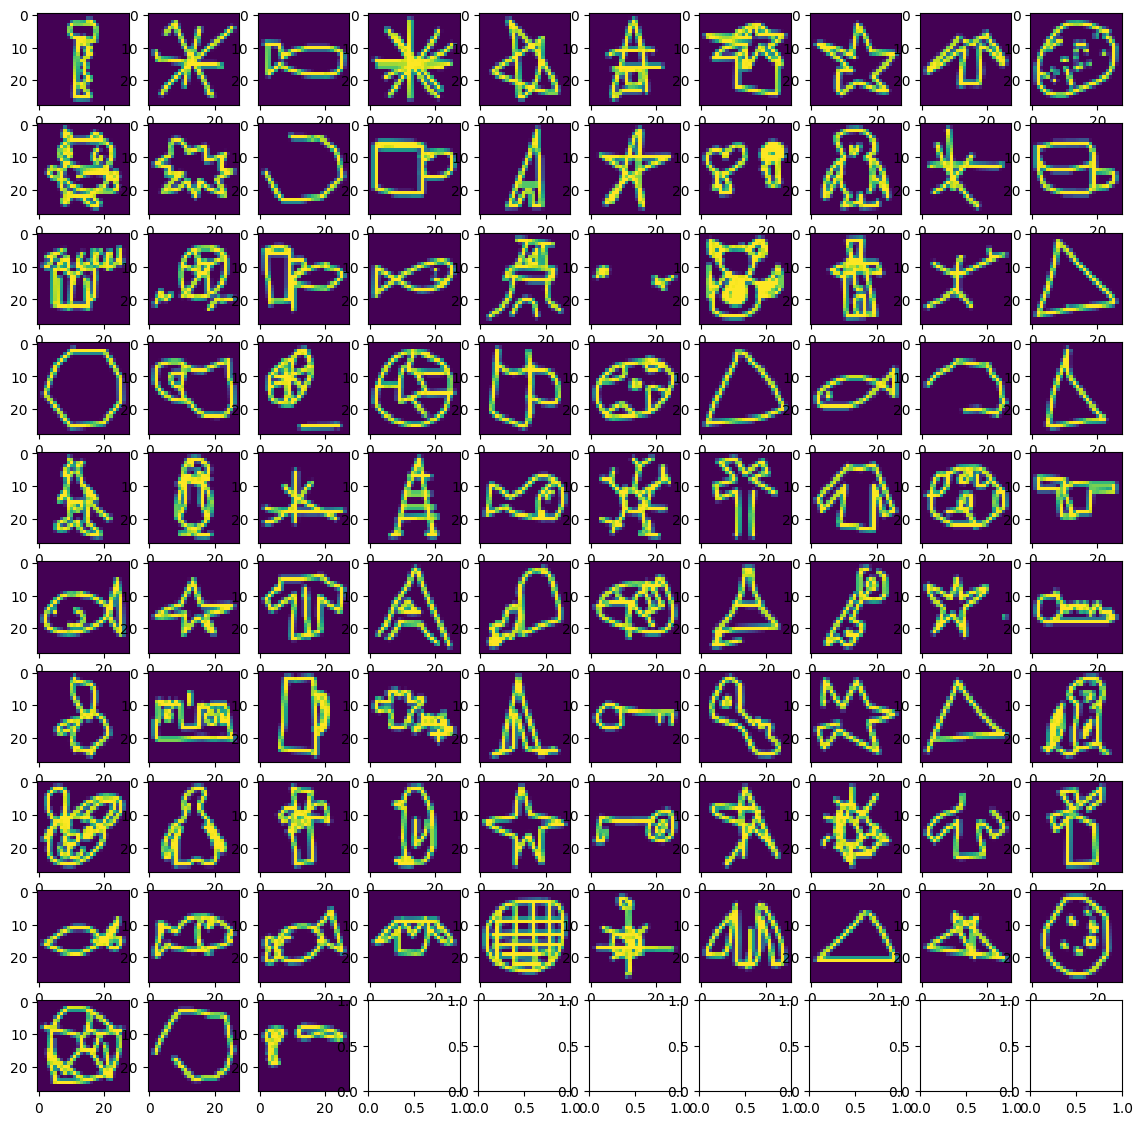

In [34]:
work = len (wrong)
gridRows = math.ceil (math.sqrt (work))
_, G = plt.subplots (gridRows, gridRows, figsize = (14,14))

index = 0
for i in range (gridRows):
    for j in range (gridRows):
        G[i, j].imshow (X_train [wrong [index]])
        index += 1
        if index == work:
            break

    if index == work:
        break


In [35]:
print("(Building Experiment 5 Model)...")

# 1. Define the Architecture
model_5= models.Sequential()

# Normalization layer
model_5.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_5.layers[0].adapt(X_train)

# First Convolutional Block 
model_5.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_5.add(layers.MaxPooling2D((2, 2)))

# Second Convolutional Block 
model_5.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_5.add(layers.MaxPooling2D((2, 2)))

# Third Convolutional Block 
model_5.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_5.add(layers.Flatten()) 
model_5.add(layers.Dense(64, activation='relu')) 
model_5.add(layers.Dropout(0.25))


# Output Layer 
model_5.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_5.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_5.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 5)...")

# 4. Train the Model
history_5 = model_5.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 5!")

(Building Experiment 5 Model)...
Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_4 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_12 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_13 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_9 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                     

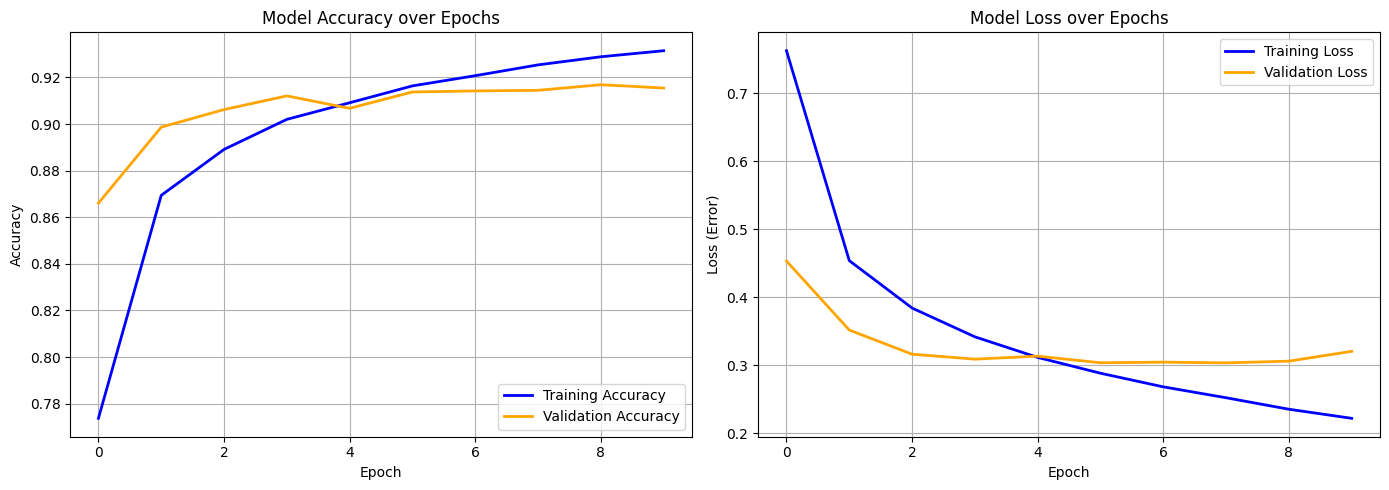

In [36]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_5.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_5.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_5.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_5.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [37]:
print("(Building Experiment 6 Model)...")

# 1. Define the Architecture
model_6= models.Sequential()

# Normalization layer
model_6.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_6.layers[0].adapt(X_train)

# First Convolutional Block
model_6.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_6.add(layers.MaxPooling2D((2, 2)))
model_6.add(layers.Dropout(0.2))

# Second Convolutional Block 
model_6.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_6.add(layers.MaxPooling2D((2, 2)))
model_6.add(layers.Dropout(0.2))

# Third Convolutional Block 
model_6.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_6.add(layers.Dropout(0.2))

# Transition to Classification
model_6.add(layers.Flatten()) 
model_6.add(layers.Dense(64, activation='relu')) 
model_6.add(layers.Dropout(0.5))

# Output Layer 
model_6.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_6.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_6.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 6)...")

# 4. Train the Model
history_6 = model_6.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 6!")

(Building Experiment 6 Model)...
Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_5 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_15 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_10 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_4 (Dropout)         (None, 13, 13, 32)        0         
                                                                 
 conv2d_16 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_11 (Ma

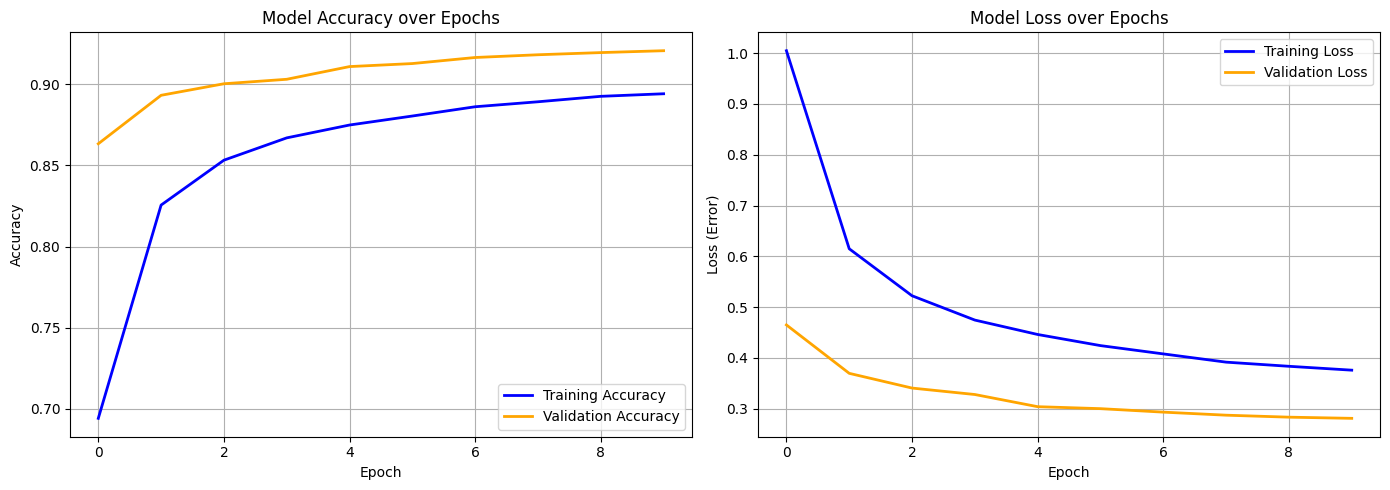

In [38]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_6.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_6.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_6.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_6.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [40]:
print("(Building Experiment 7 Model)...")

# 1. Define the Architecture
model_7= models.Sequential()

# Normalization layer
model_7.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_7.layers[0].adapt(X_train)

# First Convolutional Block
model_7.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_7.add(layers.MaxPooling2D((2, 2)))
model_7.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_7.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_7.add(layers.MaxPooling2D((2, 2)))
model_7.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_7.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_7.add(layers.Dropout(0.1))

# Transition to Classification
model_7.add(layers.Flatten()) 
model_7.add(layers.Dense(64, activation='relu')) 
model_7.add(layers.Dropout(0.5))

# Output Layer 
model_7.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_7.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_7.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 7)...")

# 4. Train the Model
history_7 = model_7.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 7!")

(Building Experiment 7 Model)...
Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_6 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_18 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_12 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_8 (Dropout)         (None, 13, 13, 32)        0         
                                                                 
 conv2d_19 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_13 (Ma

In [41]:
print("(Building Experiment 8 Model)...")

# 1. Define the Architecture
model_8= models.Sequential()

# Normalization layer
model_8.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_8.layers[0].adapt(X_train)

# First Convolutional Block
model_8.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_8.add(layers.MaxPooling2D((2, 2)))
model_8.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_8.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_8.add(layers.MaxPooling2D((2, 2)))
model_8.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_8.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_8.add(layers.Flatten()) 
model_8.add(layers.Dense(64, activation='relu')) 
model_8.add(layers.Dropout(0.5))

# Output Layer 
model_8.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_8.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_8.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 8)...")

# 4. Train the Model
history_8 = model_8.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 8!")

(Building Experiment 7 Model)...
Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_7 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_21 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_14 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_12 (Dropout)        (None, 13, 13, 32)        0         
                                                                 
 conv2d_22 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_15 (Ma

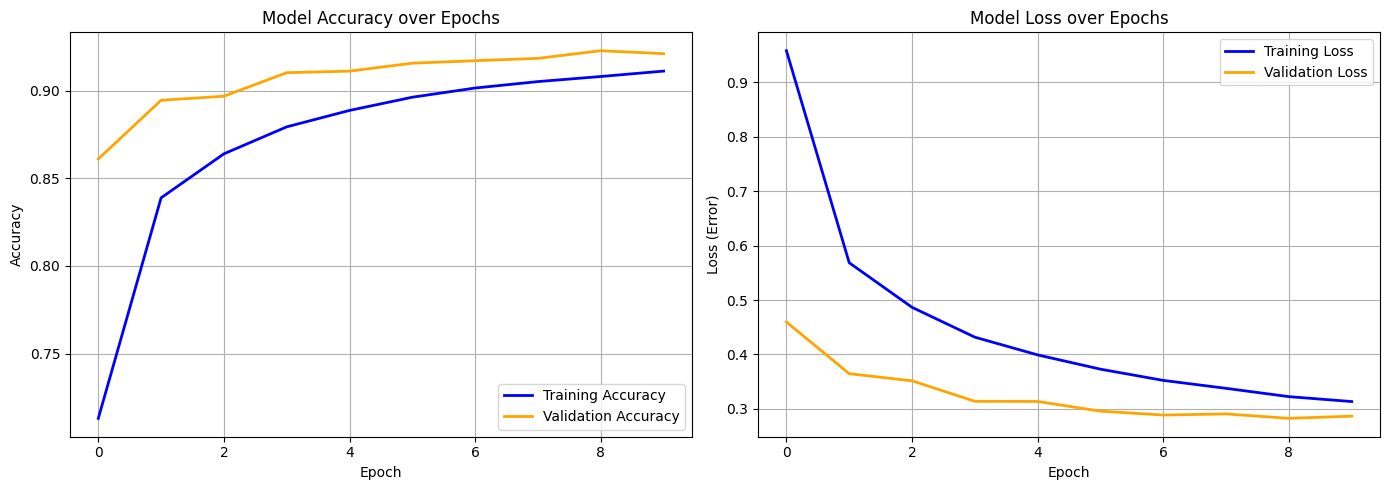

In [42]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_8.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_8.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_8.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_8.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [43]:
print("(Building Experiment 9 Model)...")

# 1. Define the Architecture
model_9= models.Sequential()

# Normalization layer
model_9.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_9.layers[0].adapt(X_train)

# First Convolutional Block
model_9.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_9.add(layers.MaxPooling2D((2, 2)))
model_9.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_9.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_9.add(layers.MaxPooling2D((2, 2)))
model_9.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_9.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_9.add(layers.Flatten()) 
model_9.add(layers.Dense(64, activation='relu')) 
model_9.add(layers.Dropout(0.3))

# Output Layer 
model_9.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_9.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_9.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 9)...")

# 4. Train the Model
history_9 = model_9.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 9!")

(Building Experiment 9 Model)...
Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_8 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_24 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_16 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_15 (Dropout)        (None, 13, 13, 32)        0         
                                                                 
 conv2d_25 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_17 (Ma

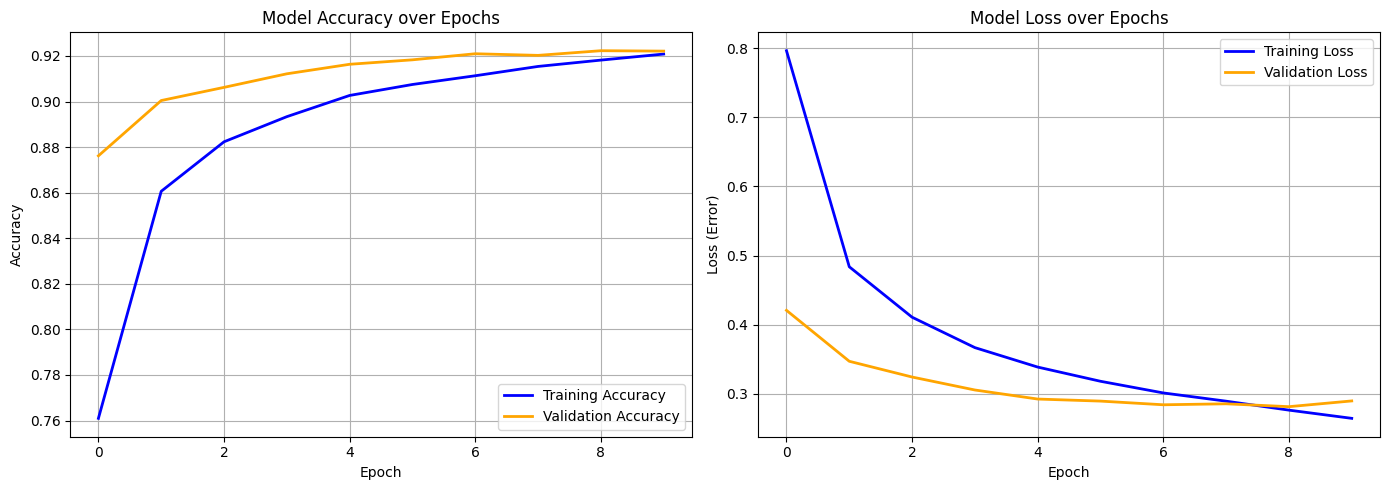

In [44]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_9.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_9.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_9.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_9.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [6]:
print("(Building Experiment 10 Model)...")

# 1. Define the Architecture
model_10= models.Sequential()

# Normalization layer
model_10.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_10.layers[0].adapt(X_train)

# First Convolutional Block
model_10.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_10.add(layers.MaxPooling2D((2, 2)))
model_10.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_10.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_10.add(layers.MaxPooling2D((2, 2)))
model_10.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_10.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_10.add(layers.Flatten()) 
model_10.add(layers.Dense(64, activation='relu')) 
model_10.add(layers.Dropout(0.4))

# Output Layer 
model_10.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_10.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_10.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 10)...")

# 4. Train the Model
history_10 = model_10.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 10!")

(Building Experiment 10 Model)...
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization (Normalizati  (None, 28, 28, 1)         3         
 on)                                                             
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 13, 13, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxP

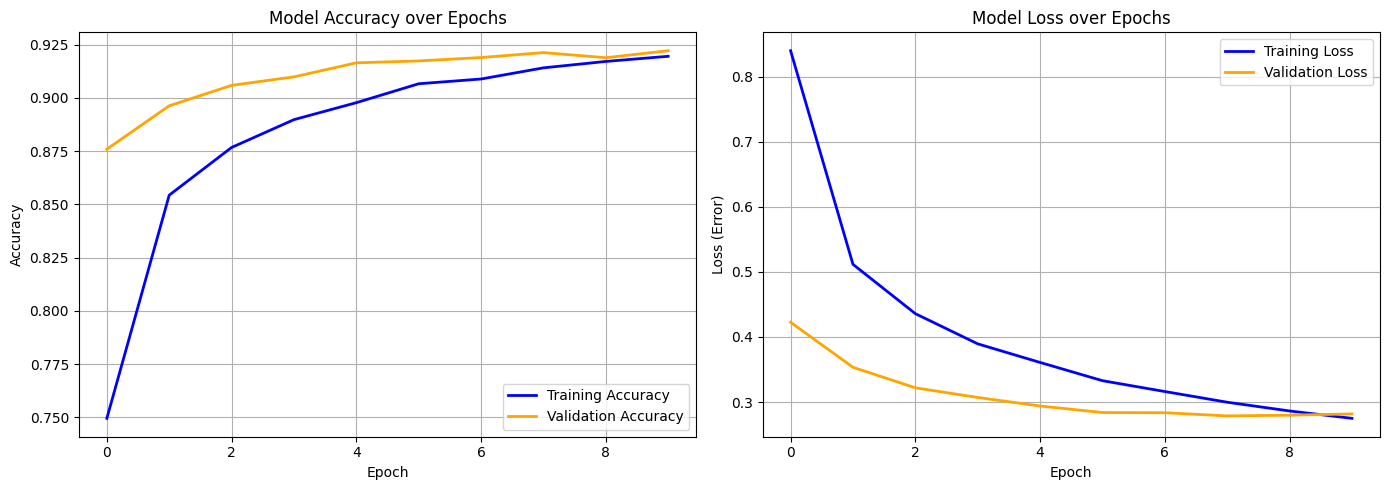

In [7]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_10.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_10.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_10.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_10.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

Generating predictions on the test set...
352/352 [==============================] - 3s 8ms/step


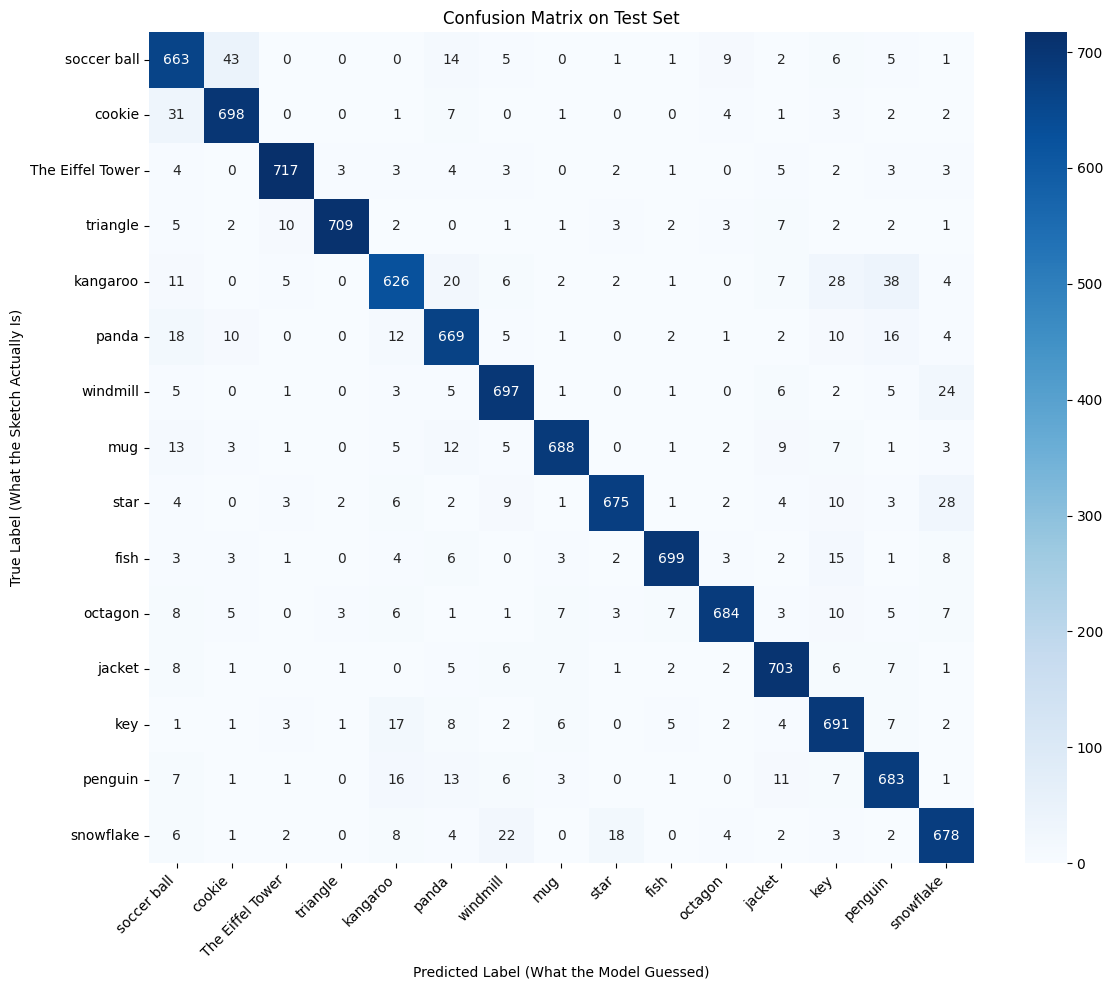

In [8]:
# 1. Get the model's predictions on the test set
print("Generating predictions on the test set...")
y_pred_probs = model_10.predict(X_test)

# 2. Convert probabilities to actual class predictions (0-14)
# np.argmax finds the index of the highest probability for each image
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 4. Plot it beautifully using Seaborn
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=categories, yticklabels=categories)
plt.title('Confusion Matrix on Test Set')
plt.ylabel('True Label (What the Sketch Actually Is)')
plt.xlabel('Predicted Label (What the Model Guessed)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [22]:
print("(Building Experiment 11 Model)...")

# 1. Define the Architecture
model_11= models.Sequential()

# First Convolutional Block
model_11.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_11.add(layers.BatchNormalization())
model_11.add(layers.MaxPooling2D((2, 2)))
# model_11.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_11.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_11.add(layers.BatchNormalization())
model_11.add(layers.MaxPooling2D((2, 2)))
# model_11.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_11.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_11.add(layers.BatchNormalization())

# Transition to Classification
model_11.add(layers.Flatten()) 
model_11.add(layers.Dense(64, activation='relu')) 
model_11.add(layers.BatchNormalization())
model_11.add(layers.Dropout(0.4))

# Output Layer 
model_11.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_11.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_11.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 11)...")

# 4. Train the Model
history_11 = model_11.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 11!")

(Building Experiment 11 Model)...
Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_26 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 batch_normalization_28 (Ba  (None, 26, 26, 32)        128       
 tchNormalization)                                               
                                                                 
 max_pooling2d_16 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_27 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 batch_normalization_29 (Ba  (None, 11, 11, 64)        256       
 tchNormalization)                                               
                   

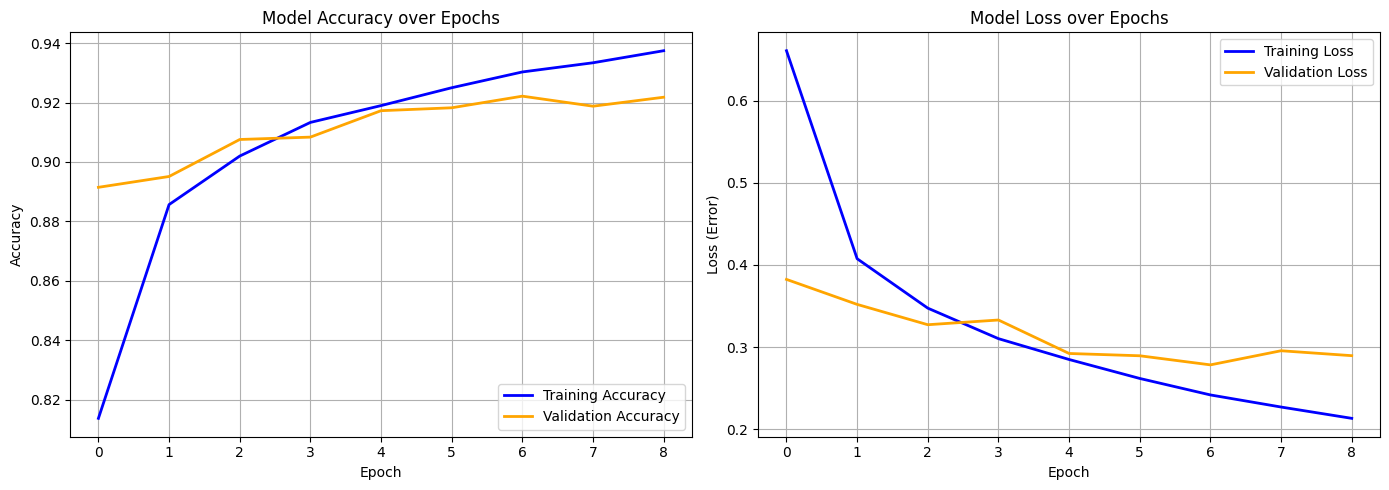

In [24]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_11.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_11.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_11.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_11.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [26]:
print("(Building Experiment 12 Model)...")

# 1. Define the Architecture
model_12= models.Sequential()

# Normalization layer
model_12.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_12.layers[0].adapt(X_train)

# First Convolutional Block
model_12.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_12.add(layers.MaxPooling2D((2, 2)))
model_12.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_12.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_12.add(layers.MaxPooling2D((2, 2)))
model_12.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_12.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_12.add(layers.Flatten()) 
model_12.add(layers.Dense(64, activation='relu')) 
model_12.add(layers.Dropout(0.35))

# Output Layer 
model_12.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_12.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_12.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 12)...")

# 4. Train the Model
history_12 = model_12.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 12!")

(Building Experiment 12 Model)...
Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_2 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_32 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_20 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_14 (Dropout)        (None, 13, 13, 32)        0         
                                                                 
 conv2d_33 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_21 (

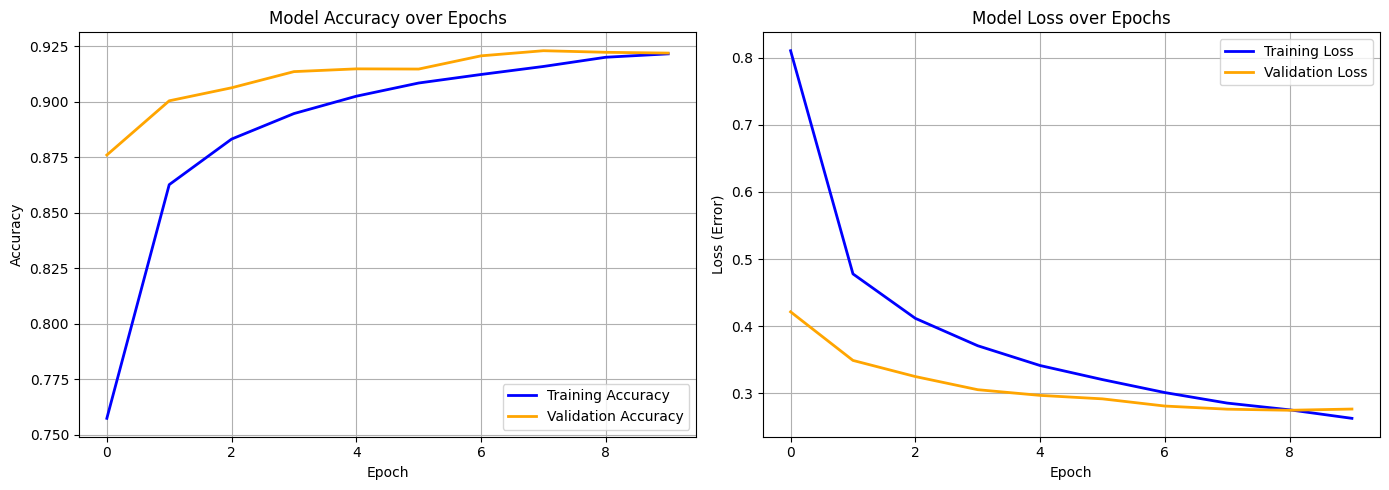

In [27]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_12.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_12.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_12.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_12.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

In [28]:
print("(Building Experiment 13 Model)...")

# 1. Define the Architecture
model_13= models.Sequential()

# Normalization layer
model_13.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_13.layers[0].adapt(X_train)

# First Convolutional Block
model_13.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_13.add(layers.MaxPooling2D((2, 2)))
model_13.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_13.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_13.add(layers.MaxPooling2D((2, 2)))
model_13.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_13.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_13.add(layers.Flatten()) 
model_13.add(layers.Dense(64, activation='relu')) 
model_13.add(layers.Dropout(0.3))

# Output Layer 
model_13.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_13.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_13.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 13)...")

# 4. Train the Model
history_13 = model_13.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 13!")

(Building Experiment 13 Model)...
Model: "sequential_13"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_3 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_35 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_22 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_17 (Dropout)        (None, 13, 13, 32)        0         
                                                                 
 conv2d_36 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_23 (

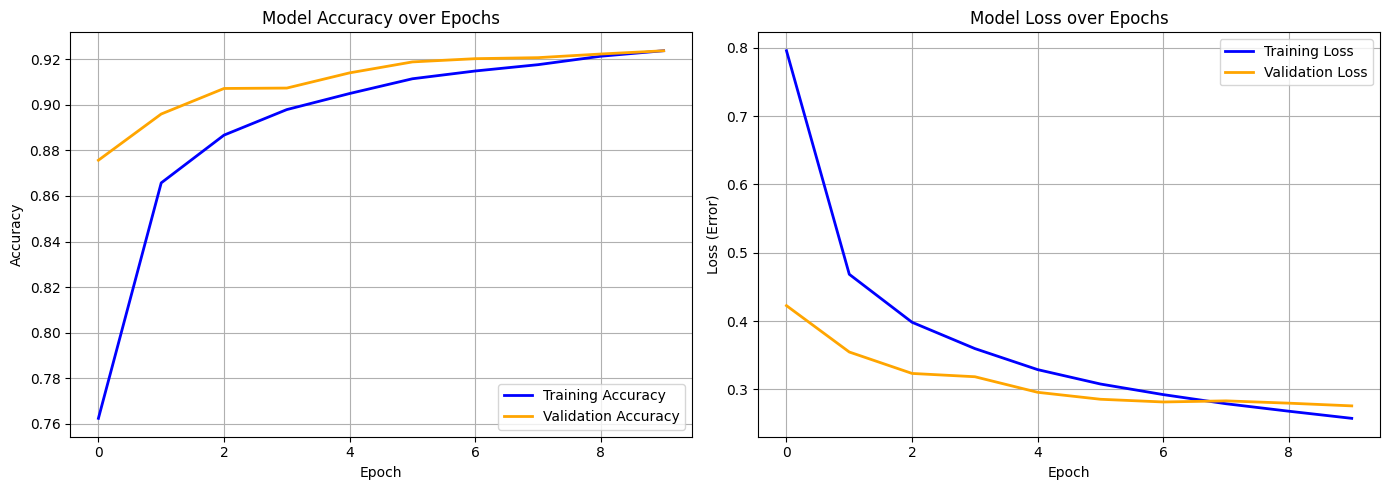

In [30]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_13.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_13.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_13.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_13.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()

Generating predictions...
1/1 [==============================] - 0s 115ms/step


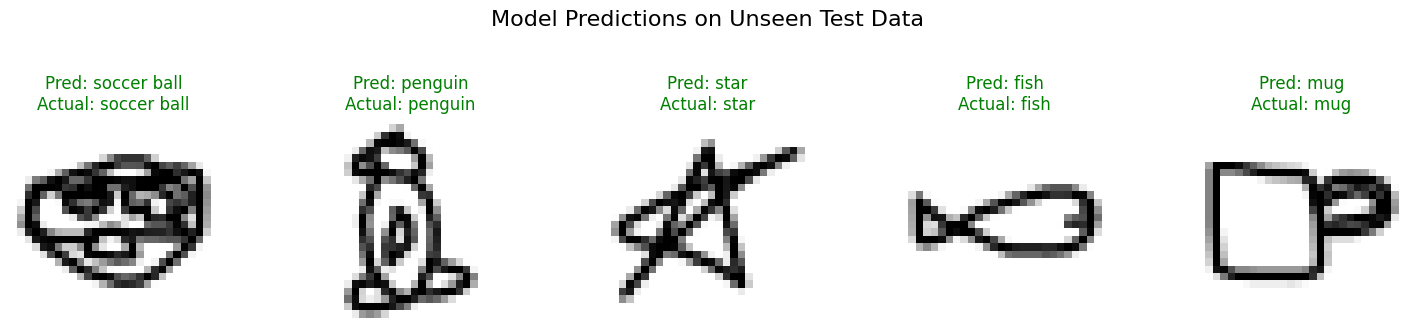

In [36]:
# 1. Map the integer labels back to our actual category names
class_names = [
    'soccer ball', 'cookie', 'The Eiffel Tower', 'triangle', 'kangaroo', 
    'panda', 'windmill', 'mug', 'star', 'fish', 
    'octagon', 'jacket', 'key', 'penguin', 'snowflake'
]

# 2. Pick 5 random images from the unseen Test Set
num_images = 5
random_indices = np.random.choice(len(X_test), num_images, replace=False)
sample_images = X_test[random_indices]
sample_labels = y_test[random_indices]

print("Generating predictions...")

# 3. Ask the model to predict these 5 images
# This returns an array of probabilities for all 15 classes for each image
predictions = model_13.predict(sample_images)

# 4. Set up the visualization
fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
fig.suptitle('Model Predictions on Unseen Test Data', fontsize=16, y=1.1)

for i, ax in enumerate(axes):
    # Reshape the image from (28, 28, 1) back to (28, 28) for Matplotlib
    img = sample_images[i].reshape(28, 28)
    
    # Get the index of the highest probability (the model's final guess)
    predicted_class_index = np.argmax(predictions[i])
    actual_class_index = sample_labels[i]
    
    # Display the image 
    # 'gray_r' reverses the colors so it looks like a black pen on white paper
    ax.imshow(img, cmap='gray_r')
    ax.axis('off') # Hide the grid axes for a cleaner look
    
    # Color-code the text: Green if correct, Red if wrong
    color = 'green' if predicted_class_index == actual_class_index else 'red'
    
    # Create the title for each subplot
    title = f"Pred: {class_names[predicted_class_index]}\nActual: {class_names[actual_class_index]}"
    ax.set_title(title, color=color, fontsize=12)

plt.tight_layout()
plt.show()

In [37]:
Z = model_13.predict(X_test, verbose=False)

Z

array([[8.8463324e-13, 1.8388848e-11, 8.6457189e-11, ..., 9.6688123e-11,
        2.0385062e-07, 2.1479383e-12],
       [2.4845380e-12, 2.4192990e-11, 9.8254703e-12, ..., 7.7635821e-11,
        2.2166761e-07, 2.4150194e-12],
       [1.1274776e-08, 7.4194283e-08, 2.5384599e-05, ..., 1.7886526e-07,
        3.7469290e-06, 7.9694682e-01],
       ...,
       [6.4592327e-14, 1.2267830e-13, 7.1277235e-08, ..., 1.2820012e-10,
        1.8903533e-11, 9.9986172e-01],
       [7.2836561e-13, 7.6898279e-14, 9.0221926e-16, ..., 4.1213673e-12,
        1.1433016e-12, 2.1137308e-16],
       [2.0101419e-01, 7.6790333e-02, 1.9697039e-03, ..., 1.0311568e-02,
        8.3776908e-03, 5.3560464e-03]], dtype=float32)

In [38]:
Z.shape

(11250, 15)

In [39]:
predictions = np.argmax(Z, axis=1)
predictions.shape

(11250,)

In [40]:
sum(predictions == y_test) / Z.shape[0]

0.9161777777777778

In [41]:
samples = np.random.randint(0, Z.shape[0], 1000)
predictions[samples]

array([13, 14,  6,  6,  6, 11,  2,  2,  5,  5, 11, 14, 14,  3, 12,  4,  9,
       14, 13,  2,  9,  0,  8, 13, 11,  0, 13,  3,  7,  9,  4, 13, 14,  1,
        4,  1, 12, 12,  5,  1,  2, 13,  1, 11,  3, 11, 13,  5,  7, 12,  3,
       11,  2,  9,  5,  4, 14,  3,  5, 11,  7, 14,  5, 13,  9,  4,  6, 11,
        3,  6, 11, 12,  6,  9,  4,  1,  7,  5,  6,  3,  5,  8,  6,  4,  7,
        7,  2,  1, 10,  3,  6,  7,  2,  9,  4,  9,  3,  8, 12,  9,  5, 14,
       10,  2, 14, 12, 14, 10, 14,  8, 14, 12,  2,  5,  5, 10,  1,  5,  1,
       12,  9, 14,  0, 11,  3,  2, 14,  7, 12, 12, 12,  5, 13,  4,  8,  6,
        8,  0,  9, 12,  8, 11,  0, 10,  2, 10,  1,  9, 11,  9,  2,  3, 10,
        2, 12, 11, 10, 12,  3,  5,  2,  9,  6, 10,  9,  8,  6,  3,  1,  0,
       14,  9, 12, 14, 10,  6,  0,  1,  9,  5, 14,  1,  0,  8,  8,  4, 14,
       13,  0,  1,  8, 12, 13,  5,  0,  3, 14, 10, 13,  5,  1, 14,  4, 12,
        2, 13,  5,  3,  8,  8,  5,  1, 13,  0,  1, 14, 14,  9,  0,  0,  2,
        0, 12,  2, 11,  6

In [42]:
predictions[samples] == y_test[samples]

array([ True,  True,  True, False,  True,  True,  True,  True, False,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,

In [43]:
wrong = np.where(predictions[samples] != y_test[samples])[0]
wrong

array([  3,   8,  11,  36,  61,  67,  83, 110, 122, 131, 142, 162, 169,
       180, 206, 216, 222, 260, 271, 275, 279, 289, 290, 292, 303, 326,
       329, 332, 335, 336, 343, 346, 413, 421, 443, 489, 517, 525, 536,
       556, 558, 571, 576, 599, 605, 666, 667, 675, 687, 689, 696, 701,
       714, 733, 736, 740, 758, 760, 770, 782, 788, 792, 805, 825, 831,
       833, 836, 841, 857, 906, 907, 912, 916, 917, 919, 949, 963, 971,
       977, 993, 994])

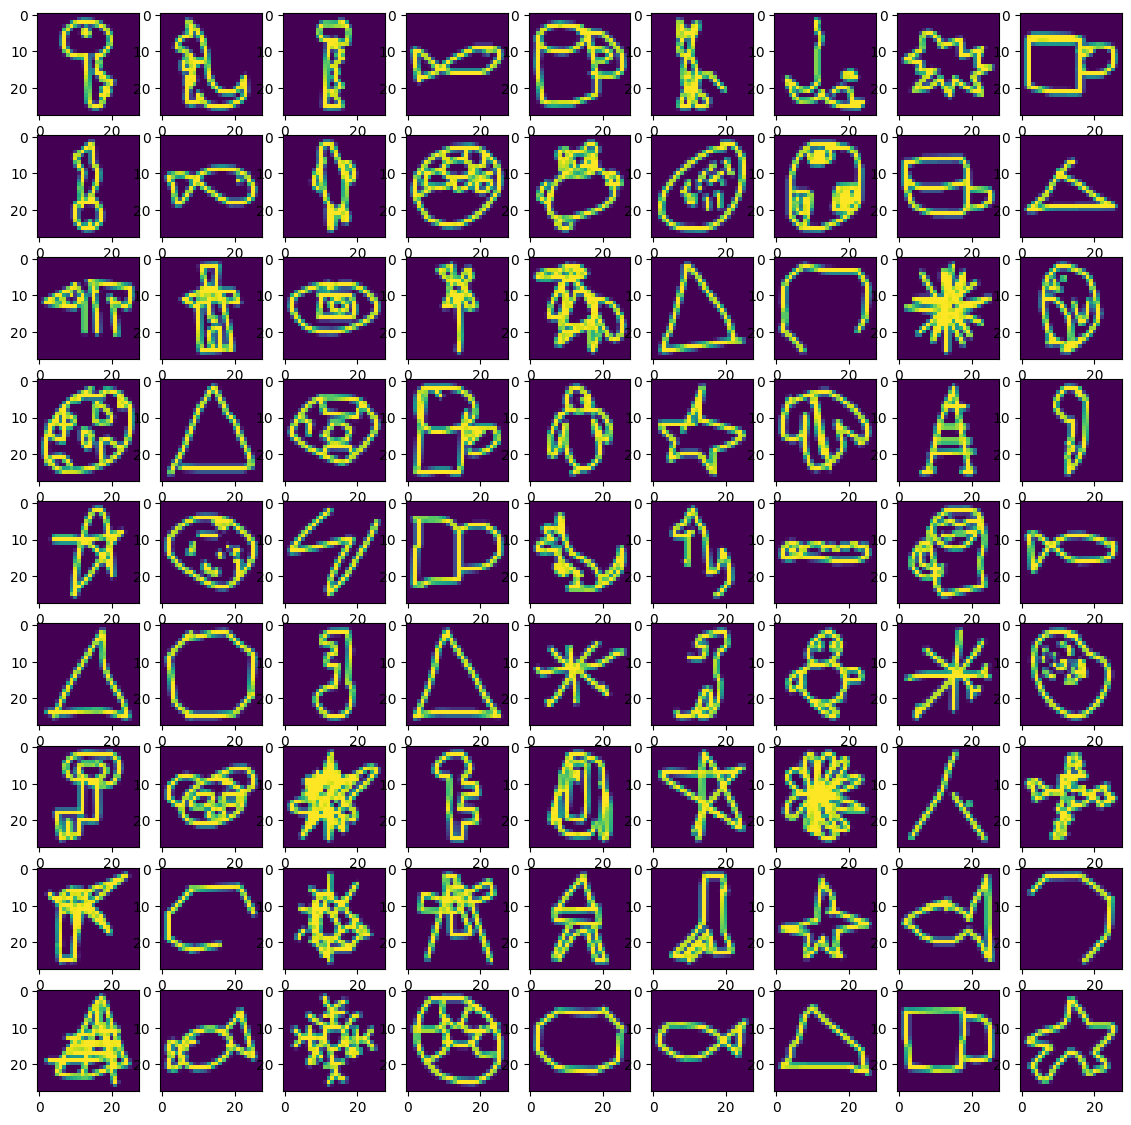

In [44]:
work = len (wrong)
gridRows = math.ceil (math.sqrt (work))
_, G = plt.subplots (gridRows, gridRows, figsize = (14,14))

index = 0
for i in range (gridRows):
    for j in range (gridRows):
        G[i, j].imshow (X_train [wrong [index]])
        index += 1
        if index == work:
            break

    if index == work:
        break


Generating predictions on the test set...
352/352 [==============================] - 2s 7ms/step


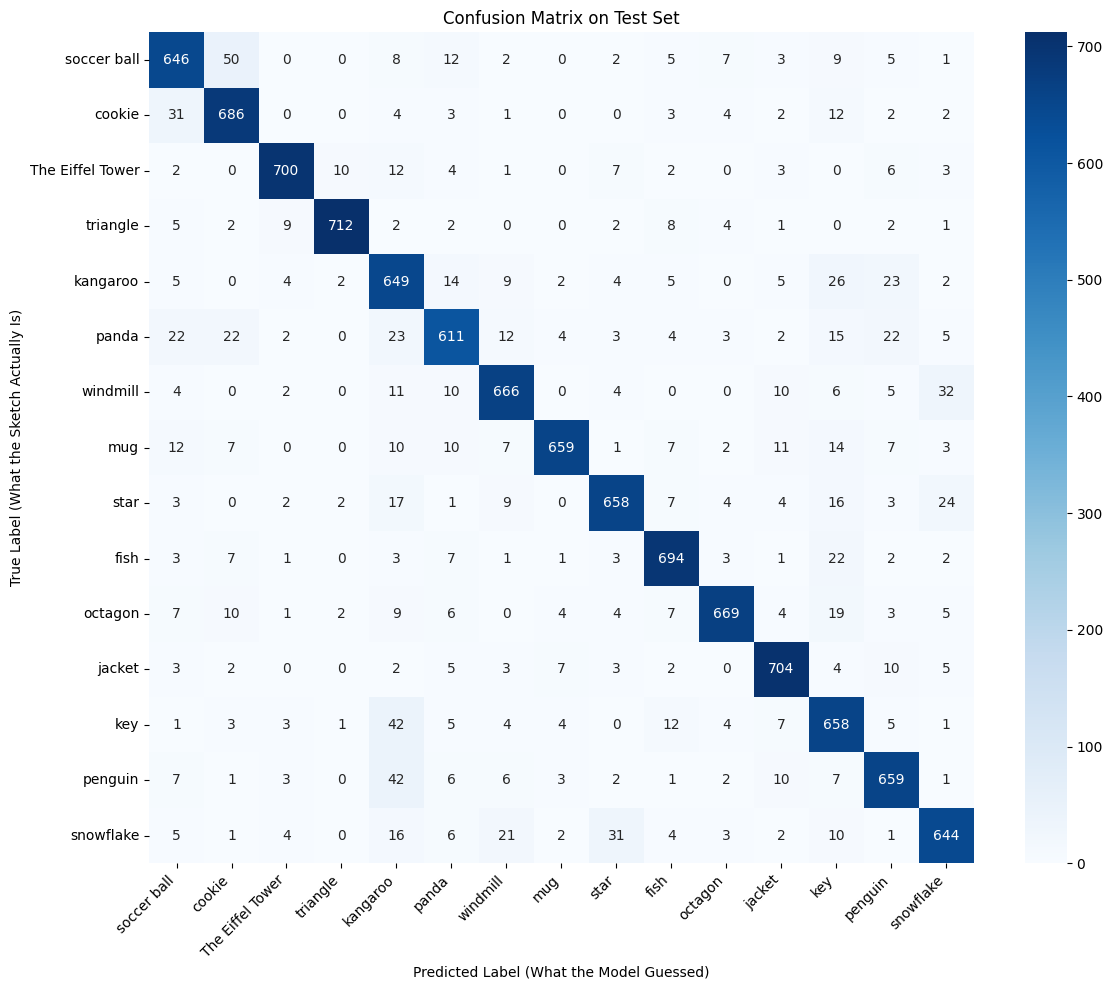

In [45]:
# 1. Get the model's predictions on the test set
print("Generating predictions on the test set...")
y_pred_probs = model_10.predict(X_test)

# 2. Convert probabilities to actual class predictions (0-14)
# np.argmax finds the index of the highest probability for each image
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 4. Plot it beautifully using Seaborn
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=categories, yticklabels=categories)
plt.title('Confusion Matrix on Test Set')
plt.ylabel('True Label (What the Sketch Actually Is)')
plt.xlabel('Predicted Label (What the Model Guessed)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [35]:
# BADDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD

print("(Building Experiment 14 Model)...")

# 1. Define the Architecture
model_14= models.Sequential()

# Normalization layer
model_14.add(keras.layers.Normalization(input_shape=(28,28,1)))
model_14.layers[0].adapt(X_train)

# First Convolutional Block
model_14.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_14.add(layers.MaxPooling2D((2, 2)))
model_14.add(layers.Dropout(0.1))

# Second Convolutional Block 
model_14.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_14.add(layers.MaxPooling2D((2, 2)))
model_14.add(layers.Dropout(0.1))

# Third Convolutional Block 
model_14.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Transition to Classification
model_14.add(layers.Flatten()) 
model_14.add(layers.Dense(64, activation='relu')) 
model_14.add(layers.Dropout(0.25))

# Output Layer 
model_14.add(layers.Dense(15, activation='softmax'))


# 2. Compile the Model
model_14.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Print summary
model_14.summary()

# 3. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("\nStarting Training (Experiment 14)...")

# 4. Train the Model
history_14 = model_14.fit(X_train, y_train, 
                        epochs=10, 
                        batch_size=64,
                        validation_data=(X_val, y_val),
                        callbacks=[early_stop])

print("\nTraining Complete for Experiment 14!")

(Building Experiment 14 Model)...
Model: "sequential_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization_7 (Normaliza  (None, 28, 28, 1)         3         
 tion)                                                           
                                                                 
 conv2d_50 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_32 (MaxPooli  (None, 13, 13, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_30 (Dropout)        (None, 13, 13, 32)        0         
                                                                 
 conv2d_51 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_33 (

KeyboardInterrupt: 

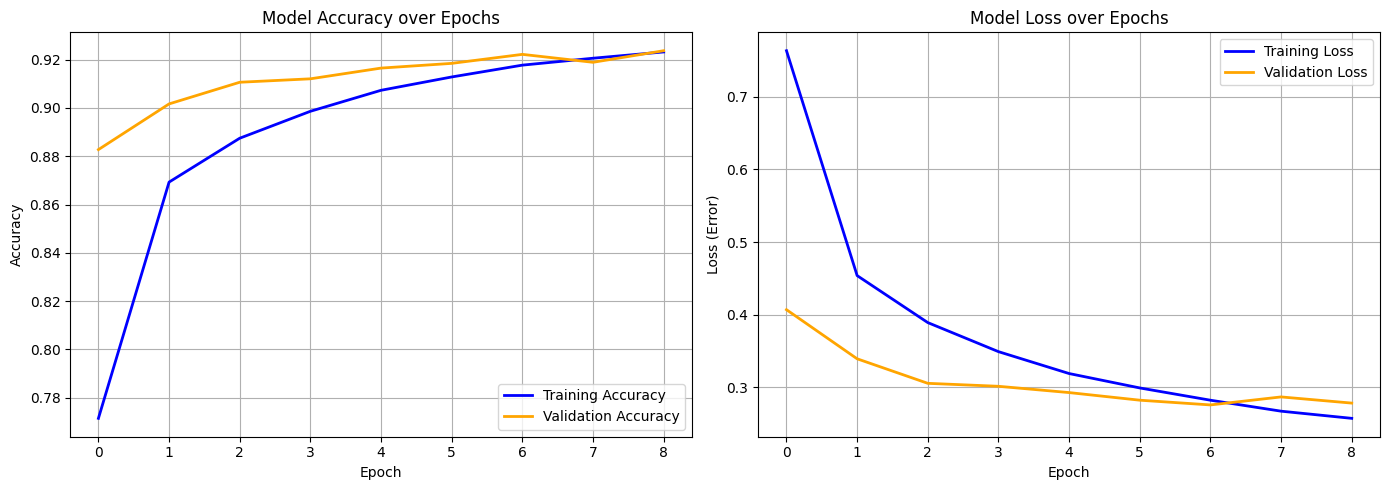

In [34]:
# Create a figure with two subplots (one for accuracy, one for loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(history_14.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history_14.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Loss (Error) ---
ax2.plot(history_14.history['loss'], label='Training Loss', color='blue', linewidth=2)
ax2.plot(history_14.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Error)')
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.show()